# Feature Engineering – Bindu's columns

My columns:
- Mother's and father's qualification
- Mother's and father's occupation
- Admission grade
- Displaced, educational special needs, debtor, tuition fees up to date, gender

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.base import clone

RANDOM_STATE = 42

In [24]:
df_clean = pd.read_csv("../data/clean/clean_data.csv")
df_clean.shape

(4424, 37)

In [25]:
columns = [
    "mothers_qualification",
    "fathers_qualification",
    "mothers_occupation",
    "fathers_occupation",
    "admission_grade",
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "target",
]

df_clean_features = df_clean[columns].copy()
df_clean_features.head()

,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,target
0,19,12,5,9,127.3,1,0,0,1,1,Dropout
1,1,3,3,3,142.5,1,0,0,0,1,Graduate
2,37,37,9,9,124.8,1,0,0,0,1,Dropout
3,38,37,5,3,119.6,1,0,0,1,0,Graduate
4,37,38,9,9,141.5,0,0,0,1,0,Graduate


## Feature Transformation – Qualifications (ordinal)

The codes are only labels, so I grouped them into levels based on the highest education finished.

0 - No schooling - 35, 36 ;
1 - Basic 1st cycle (4th year) - 37 ;
2 - Basic 2nd cycle (6th-8th year) - 38, 11, 26, 30, 29 ;
3 - Basic 3rd cycle (9th year) - 19, 27 ;
4 - Secondary not finished - 9, 10, 12, 14, 25 ;
5 - Secondary finished - 1, 13, 18, 20, 22, 31, 33 ;
6 - After secondary, no degree - 6, 39, 42 ;
7 - Bachelor / degree - 2, 3, 40, 41 ;
8 - Master - 4, 43 ;
9 - Doctorate - 5, 44 ;
Unknown - 34 (left as NaN, filled after the split)

Mother's qualification uses the same levels (it does not have codes 13, 20, 25, 31, 33).

In [26]:
# Unknowns before mapping
print("Mother unknown (34):", (df_clean_features["mothers_qualification"] == 34).sum())
print("Father unknown (34):", (df_clean_features["fathers_qualification"] == 34).sum())

Mother unknown (34): 130
Father unknown (34): 112


In [27]:
mother_qual_level = {
    35: 0, 36: 0,
    37: 1,
    38: 2, 11: 2, 26: 2, 30: 2, 29: 2,
    19: 3, 27: 3,
    9: 4, 10: 4, 12: 4, 14: 4,
    1: 5, 18: 5, 22: 5,
    6: 6, 39: 6, 42: 6,
    2: 7, 3: 7, 40: 7, 41: 7,
    4: 8, 43: 8,
    5: 9, 44: 9,
}

father_qual_level = {
    35: 0, 36: 0,
    37: 1,
    38: 2, 11: 2, 26: 2, 30: 2, 29: 2,
    19: 3, 27: 3,
    9: 4, 10: 4, 12: 4, 14: 4, 25: 4,
    1: 5, 13: 5, 18: 5, 20: 5, 22: 5, 31: 5, 33: 5,
    6: 6, 39: 6, 42: 6,
    2: 7, 3: 7, 40: 7, 41: 7,
    4: 8, 43: 8,
    5: 9, 44: 9,
}

df_clean_features["mothers_qualification"] = df_clean_features["mothers_qualification"].map(mother_qual_level)
df_clean_features["fathers_qualification"] = df_clean_features["fathers_qualification"].map(father_qual_level)

# Only the unknowns (34) should be NaN now
df_clean_features[["mothers_qualification", "fathers_qualification"]].isna().sum()

mothers_qualification    130
fathers_qualification    112
dtype: int64

## Feature Transformation – Occupations (nominal)

Occupation has no order, so I grouped the codes into main groups and will use one-hot encoding.
The middle number of the 3-digit codes gives the group (e.g. 122, 123 are specialists).
90 (other) and 99 (blank) go into other_unknown.

In [28]:
mother_occ_group = {
    0: "student",
    1: "managers",
    2: "specialists", 122: "specialists", 123: "specialists", 125: "specialists",
    3: "technicians", 131: "technicians", 132: "technicians", 134: "technicians",
    4: "administrative", 141: "administrative", 143: "administrative", 144: "administrative",
    5: "services_sellers", 151: "services_sellers", 152: "services_sellers", 153: "services_sellers",
    6: "farmers",
    7: "skilled_industry", 171: "skilled_industry", 173: "skilled_industry", 175: "skilled_industry",
    8: "machine_operators",
    9: "unskilled", 191: "unskilled", 192: "unskilled", 193: "unskilled", 194: "unskilled",
    10: "armed_forces",
    90: "other_unknown", 99: "other_unknown",
}

father_occ_group = {
    0: "student",
    1: "managers", 112: "managers", 114: "managers",
    2: "specialists", 121: "specialists", 122: "specialists", 123: "specialists", 124: "specialists",
    3: "technicians", 131: "technicians", 132: "technicians", 134: "technicians", 135: "technicians",
    4: "administrative", 141: "administrative", 143: "administrative", 144: "administrative",
    5: "services_sellers", 151: "services_sellers", 152: "services_sellers", 153: "services_sellers", 154: "services_sellers",
    6: "farmers", 161: "farmers", 163: "farmers",
    7: "skilled_industry", 171: "skilled_industry", 172: "skilled_industry", 174: "skilled_industry", 175: "skilled_industry",
    8: "machine_operators", 181: "machine_operators", 182: "machine_operators", 183: "machine_operators",
    9: "unskilled", 192: "unskilled", 193: "unskilled", 194: "unskilled", 195: "unskilled",
    10: "armed_forces", 101: "armed_forces", 102: "armed_forces", 103: "armed_forces",
    90: "other_unknown", 99: "other_unknown",
}

df_clean_features["mothers_occupation"] = df_clean_features["mothers_occupation"].map(mother_occ_group)
df_clean_features["fathers_occupation"] = df_clean_features["fathers_occupation"].map(father_occ_group)

# Every code is mapped, so this should be 0 for both
df_clean_features[["mothers_occupation", "fathers_occupation"]].isna().sum()

mothers_occupation    0
fathers_occupation    0
dtype: int64

In [29]:
df_clean_features["mothers_occupation"].value_counts()

mothers_occupation
unskilled            1623
administrative        834
services_sellers      537
technicians           359
specialists           328
skilled_industry      279
student               144
managers              102
farmers                91
other_unknown          87
machine_operators      36
armed_forces            4
Name: count, dtype: int64

In [30]:
df_clean_features["fathers_occupation"].value_counts()

fathers_occupation
unskilled            1034
skilled_industry      681
services_sellers      523
administrative        396
technicians           390
machine_operators     326
armed_forces          273
farmers               248
specialists           204
managers              137
student               128
other_unknown          84
Name: count, dtype: int64

## Binary features

In [31]:
binary_features = [
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
]

for column in binary_features:
    print(df_clean_features.groupby(column)["target"].value_counts(normalize=True).round(3))
    print()

displaced  target  
0          Graduate    0.443
           Dropout     0.376
           Enrolled    0.181
1          Graduate    0.546
           Dropout     0.276
           Enrolled    0.178
Name: proportion, dtype: float64

educational_special_needs  target  
0                          Graduate    0.500
                           Dropout     0.321
                           Enrolled    0.179
1                          Graduate    0.451
                           Dropout     0.333
                           Enrolled    0.216
Name: proportion, dtype: float64

debtor  target  
0       Graduate    0.538
        Dropout     0.283
        Enrolled    0.180
1       Dropout     0.620
        Graduate    0.201
        Enrolled    0.179
Name: proportion, dtype: float64

tuition_fees_up_to_date  target  
0                        Dropout     0.866
                         Enrolled    0.080
                         Graduate    0.055
1                        Graduate    0.560
                   

## Numerical features

In [32]:
df_clean_features["admission_grade"].describe()

count    4424.000000
mean      126.978119
std        14.482001
min        95.000000
25%       117.900000
50%       126.100000
75%       134.800000
max       190.000000
Name: admission_grade, dtype: float64

In [33]:
df_clean_features.groupby("target")["admission_grade"].mean().round(2)

target
Dropout     124.96
Enrolled    125.53
Graduate    128.79
Name: admission_grade, dtype: float64

### Observations

- Displaced students drop out less (28% vs 38%) and graduate more (55% vs 44%).
- Only 51 students have educational special needs, and their outcomes are almost the same as the others. Weak feature.
- Debtors drop out much more (62% vs 28%).
- Students with tuition fees not up to date drop out the most (87%). This is the strongest of my binary features, but fees may stop because the student already left.
- Men drop out more (45% vs 25%), women graduate more (58% vs 35%).
- Admission grade is between 95 and 190, no missing values.
- Mother's qualification has 130 unknowns and father's has 112 – they will be filled after the split.

## Train/test split

In [34]:
X = df_clean_features.drop(columns="target")
y = df_clean_features["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (3539, 10) Test: (885, 10)


In [35]:
# Feature groups – used by the tests and the pipeline
ordinal_features   = ["mothers_qualification", "fathers_qualification"]
nominal_features   = ["mothers_occupation", "fathers_occupation"]
numerical_features = ["admission_grade"]
binary_features    = ["displaced", "debtor", "tuition_fees_up_to_date", "gender"]  # educational_special_needs removed (p = 0.786)

## Chi-square test – Relationship between categorical features and the target

I used the chi-square test (from scipy.stats) to check if my categorical and binary features are related to the target (Dropout, Enrolled, Graduate).

- p-value < 0.05 means the feature is related to the target (not chance).
- Cramér's V shows how strong the relationship is (0 = none, 1 = very strong).

The test is done on the training data only, because I use it to decide which features to keep.

In [36]:
from scipy.stats import chi2_contingency

cat_cols = nominal_features + ordinal_features + binary_features

results = []
for column in cat_cols:
    table = pd.crosstab(X_train[column], y_train)
    chi2, p_value, dof, expected = chi2_contingency(table)

    # Cramér's V: strength of the relationship (0 = none, 1 = perfect)
    n = table.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

    results.append({
        "feature": column,
        "chi2": round(chi2, 1),
        "p_value": p_value,
        "cramers_v": round(cramers_v, 3),
    })

chi2_results = pd.DataFrame(results).sort_values("cramers_v", ascending=False)
chi2_results

,feature,chi2,p_value,cramers_v
6,tuition_fees_up_to_date,661.0,2.920120e-144,0.432
5,debtor,226.1,7.918058e-50,0.253
7,gender,184.2,1.021572e-40,0.228
0,mothers_occupation,170.2,6.839990e-25,0.155
1,fathers_occupation,146.1,2.572191e-20,0.144
4,displaced,48.7,2.634508e-11,0.117
2,mothers_qualification,64.3,4.022613e-07,0.097
3,fathers_qualification,64.0,4.622236e-07,0.096


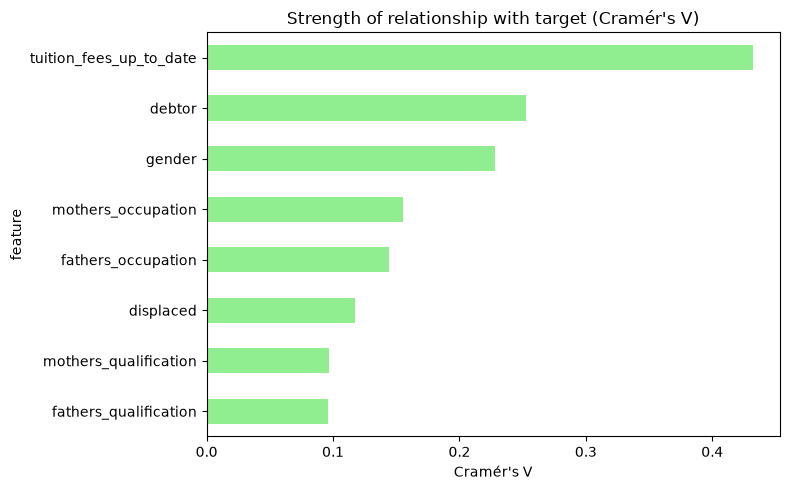

In [37]:
chi2_results.set_index("feature")["cramers_v"].sort_values().plot(
    kind="barh", color="lightgreen", figsize=(8, 5)
)
plt.title("Strength of relationship with target (Cramér's V)")
plt.xlabel("Cramér's V")
plt.tight_layout()
plt.show()

Insights:
- All features except educational special needs have p < 0.05, so they are related to the target.
- Tuition fees up to date is by far the strongest feature (0.432). Students who are behind on fees mostly drop out.
- Debtor and gender also have a clear relationship with the target.
- Parents' occupations matter more than parents' qualifications.
- Parents' qualifications are related to the target, but the relationship is weak (about 0.1). I keep them for now and will check if the model changes without them.
- Educational special needs has p = 0.786, so there is no real relationship with the target. Only 51 students have special needs. I drop this feature.

## Admission grade – Relationship with the target

Admission grade is the score students had when they were admitted to their programme (0–200).
It is numerical and the target is categorical (Dropout, Enrolled, Graduate), so I used ANOVA instead of chi-square.

Steps:
1. Compared the admission grade of each group with a summary table and a boxplot.
2. Used the ANOVA test to check if the average admission grade is really different between the groups.

- p-value < 0.05 means the average admission grade differs between Dropout, Enrolled and Graduate.

Done on the training data only.

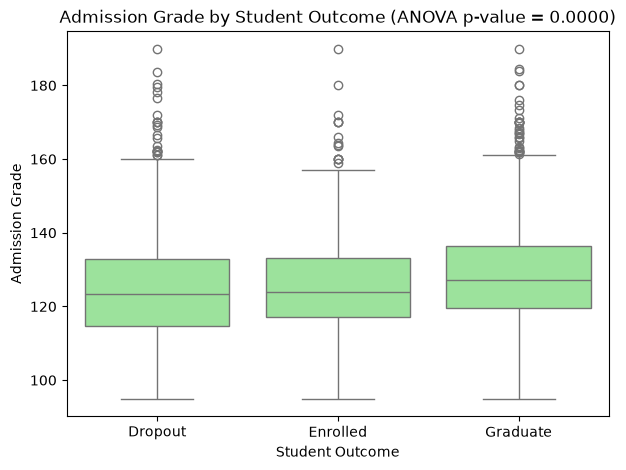

,feature,test,p_value,significant (p < 0.05),mean Dropout,mean Enrolled,mean Graduate
0,admission_grade,ANOVA,0.0,Yes,124.81,125.49,128.7


In [38]:
plt.figure(figsize=(7, 5))
sns.boxplot(x=y_train, y=X_train["admission_grade"],
            order=["Dropout", "Enrolled", "Graduate"], color="lightgreen")
plt.title(f"Admission Grade by Student Outcome (ANOVA p-value = {p_value:.4f})")
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")
plt.show()


from scipy.stats import f_oneway

# ANOVA – 3 classes (Dropout, Enrolled, Graduate)
groups = [X_train.loc[y_train == t, "admission_grade"] for t in ["Dropout", "Enrolled", "Graduate"]]
_, p_value = f_oneway(*groups)

anova_results = pd.DataFrame([{
    "feature": "admission_grade",
    "test": "ANOVA",
    "p_value": round(p_value, 4),
    "significant (p < 0.05)": "Yes" if p_value < 0.05 else "No",
    "mean Dropout": round(groups[0].mean(), 2),
    "mean Enrolled": round(groups[1].mean(), 2),
    "mean Graduate": round(groups[2].mean(), 2),
}])
anova_results

### Result

1. p-value < 0.0001, so admission grade is related to the target. Graduates entered with slightly higher grades (128.7) than dropout students (124.8).
2. The difference is small, so admission grade is a weak feature.

## Mother's occupation vs Father's occupation

I checked if the parents' occupations are related, using chi-square and Cramér's V on the training data.


In [39]:
table = pd.crosstab(X_train["mothers_occupation"], X_train["fathers_occupation"])
chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

print("p-value:", round(p_value, 4))
print("Cramér's V:", round(cramers_v, 3))

p-value: 0.0
Cramér's V: 0.408


Parents' occupations are partly related (Cramér's V = 0.408), but they still carry different information, so I keep both.

## Debtor vs Tuition fees up to date

I checked if these two columns give the same information, using chi-square and Cramér's V on the training data.

- Cramér's V = 0.418, which is a moderate relationship.
- Many debtors are also behind on their fees, but not all of them.
- So the two columns overlap partly but still have different information.

Decision: keep both features.
Note: because they overlap, they count a bit double in the KNN distance.
This can be checked later by comparing the model with and without debtor.

In [40]:
pd.crosstab(X_train["debtor"], X_train["tuition_fees_up_to_date"])

tuition_fees_up_to_date,0,1
debtor,,
0,223,2927
1,196,193


In [41]:
table = pd.crosstab(X_train["debtor"], X_train["tuition_fees_up_to_date"])
chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

print("p-value:", round(p_value, 4))
print("Cramér's V:", round(cramers_v, 3))

p-value: 0.0
Cramér's V: 0.418


## Preprocessing

- Ordinal (qualifications): fill unknowns with the median level  then MinMax scaling
- Nominal (occupations): one-hot encoding
- Numerical (admission grade): MinMax scaling
- Binary: already 0/1, kept as they are

Everything is fitted on the training data only.

## Baseline model – KNN with my features only

In [42]:
knn_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])

knn_pipeline.fit(X_train, y_train)

y_pred_train = knn_pipeline.predict(X_train)
y_pred_test = knn_pipeline.predict(X_test)

print("Train accuracy:", round(accuracy_score(y_train, y_pred_train), 3))
print("Test accuracy:", round(accuracy_score(y_test, y_pred_test), 3))

NameError: name 'preprocessor' is not defined

In [43]:
print(classification_report(y_test, y_pred_test))

NameError: name 'y_pred_test' is not defined

### KNN results – my features only

- Test accuracy is 0.51, only slightly better than always predicting "Graduate" (0.50).
- Graduate is predicted best (recall 0.67), dropout is moderate (recall 0.46),
  and enrolled is predicted very poorly (recall 0.16).
- Enrolled is the smallest class and sits between dropout and graduate, so it is hard to separate.
- My features alone are not enough to predict the outcome well, because they do not include
  academic performance (grades, approved units).
- Next step: combine my features with the team's features, and compare with the
  Dropout vs Graduate version of the target.

I first built a 3-class model (Dropout, Enrolled, Graduate) as a baseline.
Enrolled was predicted very poorly (recall 0.16), and the team decided to train
the final model on Graduate vs Dropout only. Enrolled students are used for prediction afterwards.


## Predicting dropout risk for enrolled students

Enrolled students are not used for training or testing, because we don't know their final outcome yet.
I trained and tested the model only on students who already graduated or dropped out,
and then used it to predict which enrolled students might drop out.

In [44]:
# Separate known outcomes and enrolled students

df_clean_model = df_clean_features[df_clean_features["target"] != "Enrolled"].copy()
df_clean_enrolled = df_clean_features[df_clean_features["target"] == "Enrolled"].copy()

X_bi = df_clean_model.drop(columns="target")
y_bi = df_clean_model["target"]

X_bi_train, X_bi_test, y_bi_train, y_bi_test = train_test_split(
    X_bi, y_bi, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bi
)

# Same preprocessing, fresh copy
bi_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])
bi_pipeline.fit(X_bi_train, y_bi_train)

print("Train accuracy:", round(bi_pipeline.score(X_bi_train, y_bi_train), 3))
print("Test accuracy:", round(bi_pipeline.score(X_bi_test, y_bi_test), 3))
print(classification_report(y_bi_test, bi_pipeline.predict(X_bi_test)))

NameError: name 'preprocessor' is not defined

In [22]:
X_enrolled = df_clean_enrolled.drop(columns="target")

df_clean_enrolled["predicted"] = bi_pipeline.predict(X_enrolled)
dropout_col = list(bi_pipeline.classes_).index("Dropout")
df_clean_enrolled["dropout_risk"] = bi_pipeline.predict_proba(X_enrolled)[:, dropout_col]

print(df_clean_enrolled["predicted"].value_counts())
df_clean_enrolled.sort_values("dropout_risk", ascending=False).head(10)

NameError: name 'bi_pipeline' is not defined

Out of 794 enrolled students, 181 are predicted to drop out and 613 to graduate.
The students with the highest dropout risk could be offered support first.
Because the model uses only my features, these predictions are a first estimate, not a final result.

# KNN Model – Graduate vs Dropout (without enrolled students)

In [ ]:
# My columns + target
my_columns = ["mothers_qualification", "fathers_qualification",
              "mothers_occupation", "fathers_occupation",
              "admission_grade", "displaced", "educational_special_needs",
              "debtor", "tuition_fees_up_to_date", "gender", "target"]

# Remove enrolled students – train on Graduate vs Dropout only
df_clean_model = df_clean_clean[my_columns][df_clean_clean["target"] != "Enrolled"].copy()
df_clean_model["target"].value_counts()

In [ ]:
#Train/test split 

from sklearn.model_selection import train_test_split

X = df_model.drop(columns="target")
y = df_model["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

In [ ]:
# Feature groups
ordinal_features   = ["mothers_qualification", "fathers_qualification"]
nominal_features   = ["mothers_occupation", "fathers_occupation"]
numerical_features = ["admission_grade"]
binary_features    = ["displaced", "educational_special_needs", "debtor", "tuition_fees_up_to_date", "gender"]

In [ ]:
# Chi-square test (categorical and binary vs target)
from scipy.stats import chi2_contingency

results = []
for column in nominal_features + ordinal_features + binary_features:
    table = pd.crosstab(X_train[column], y_train)
    chi2, p_value, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    results.append({"feature": column, "p_value": p_value,
                    "significant (p < 0.05)": "Yes" if p_value < 0.05 else "No",
                    "cramers_v": round(cramers_v, 3)})

chi2_results = pd.DataFrame(results).sort_values("cramers_v", ascending=False)
chi2_results.style.format({"p_value": "{:.4f}"})

In [ ]:
# Relationships between features
def cramers_v_between(col1, col2):
    table = pd.crosstab(X_train[col1], X_train[col2])
    chi2, p_value, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    print(col1, "vs", col2, "| p-value:", round(p_value, 4), "| Cramér's V:", round(v, 3))

cramers_v_between("debtor", "tuition_fees_up_to_date")
cramers_v_between("mothers_occupation", "fathers_occupation")

In [ ]:
#ANOVA for admission grade

from scipy.stats import f_oneway

display(X_train.groupby(y_train)["admission_grade"].describe().round(2))

groups = [X_train.loc[y_train == t, "admission_grade"] for t in ["Dropout", "Graduate"]]
_, p_value = f_oneway(*groups)
print("p-value:", round(p_value, 4))

sns.boxplot(x=y_train, y=X_train["admission_grade"], order=["Dropout", "Graduate"], color="lightgreen")
plt.title(f"Admission Grade by Student Outcome (ANOVA p-value = {p_value:.4f})")
plt.show()

In [ ]:
#Decision (remove educational special needs from the model)
model_binary_features = [c for c in binary_features if c != "educational_special_needs"]
model_binary_features

In [ ]:
# Preprocessing and KNN pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

preprocessor = ColumnTransformer([
    ("ordinal", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scaler", MinMaxScaler())]), ordinal_features),
    ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_features),
    ("numerical", MinMaxScaler(), numerical_features),
    ("binary", "passthrough", model_binary_features),
])

knn_pipeline = Pipeline([("preprocess", preprocessor),
                         ("model", KNeighborsClassifier(n_neighbors=5))])
knn_pipeline.fit(X_train, y_train)

In [ ]:
#Evaluation
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

y_pred_train = knn_pipeline.predict(X_train)
y_pred_test = knn_pipeline.predict(X_test)

print("Train accuracy:", round(accuracy_score(y_train, y_pred_train), 3))
print("Test accuracy:", round(accuracy_score(y_test, y_pred_test), 3))
print(classification_report(y_test, y_pred_test))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=["Dropout", "Graduate"], cmap="Blues")
plt.title("Confusion matrix – Test")
plt.show()